# Student ML Project: Spam Message Classification

## Project Idea
In this project, you will build a machine learning model that classifies text messages as:

- **ham**: normal message
- **spam**: unwanted promotional or scam message

This is a **text classification / NLP project**, not an image project.

## Student Objectives
By the end of this notebook, you should be able to:

1. Create and load a text dataset.
2. Explore text data.
3. Clean text messages.
4. Convert text into numerical features using **TF-IDF**.
5. Split data into training and testing sets.
6. Train different machine learning models.
7. Compare model accuracy.
8. Evaluate the best model using a confusion matrix and classification report.
9. Test the model using new custom messages.

---

## 1. Import Libraries

### TODO
Run the cell below to import the required libraries.


In [ ]:
# Data handling
import pandas as pd
import numpy as np

# Text processing
import re
import string

# Visualization
import matplotlib.pyplot as plt

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Models
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

## 2. Create the Text Dataset

The dataset contains short text messages and their labels.

### TODO
1. Run the cell to create the dataset.
2. Convert it into a DataFrame.
3. Display the first rows.


In [ ]:
df = pd.read_csv("/content/real_sms_spam_dataset_sample.csv")
df.head()

,label,label_num,message
0,ham,0,"Go until jurong point, crazy.. Available only ..."
1,ham,0,Ok lar... Joking wif u oni...
2,spam,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,0,U dun say so early hor... U c already then say...
4,ham,0,"Nah I don't think he goes to usf, he lives aro..."


## 3. Understand the Dataset

### TODO
Write code to answer these questions:

1. How many rows and columns are in the dataset?
2. What are the column names?
3. What are the data types?
4. How many spam and ham messages are there?
5. Are there missing values?
6. Are there duplicated messages?


In [ ]:
# TODO: Display the shape of the dataset
df.shape

(193, 3)

In [ ]:
# TODO: Display column names
df.columns

Index(['label', 'label_num', 'message'], dtype='object')

In [ ]:
# TODO: Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   label      193 non-null    object
 1   label_num  193 non-null    int64 
 2   message    193 non-null    object
dtypes: int64(1), object(2)
memory usage: 4.7+ KB


In [ ]:
# TODO: Count spam and ham messages
df['label'].value_counts()

,count
label,
ham,166
spam,27


In [ ]:
# TODO: Check missing values
df.isnull().sum()

,0
label,0
label_num,0
message,0


In [ ]:
# TODO: Check duplicated rows
df.duplicated().sum()

np.int64(0)

## 4. Text Length Analysis

Text length can sometimes help us understand patterns in spam and ham messages.

### TODO
1. Create a new column called `message_length`.
2. Calculate the number of characters in each message.
3. Compare message length between spam and ham.


In [ ]:
# TODO: Create message_length column
message_length=df['message'].str.len()
df['message_length']=message_length
df.head()

,label,label_num,message,message_length
0,ham,0,"Go until jurong point, crazy.. Available only ...",111
1,ham,0,Ok lar... Joking wif u oni...,29
2,spam,1,Free entry in 2 a wkly comp to win FA Cup fina...,111
3,ham,0,U dun say so early hor... U c already then say...,49
4,ham,0,"Nah I don't think he goes to usf, he lives aro...",61


In [ ]:
# TODO: Show average message length for each label
df.groupby('label')['message_length'].mean()

,message_length
label,
ham,49.373494
spam,84.666667


<Axes: xlabel='label'>

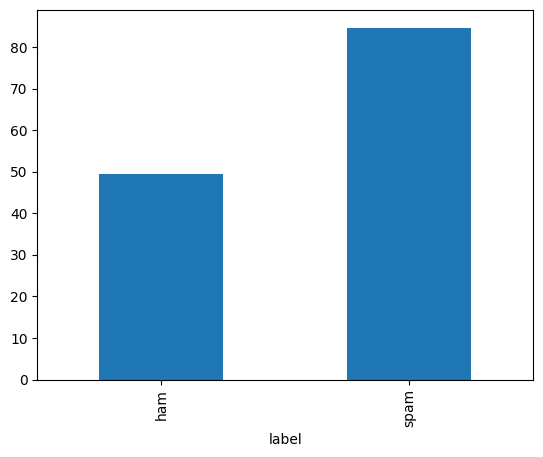

In [ ]:
# TODO: Plot message length by label
df.groupby('label')['message_length'].mean().plot(kind='bar')

## 5. Clean the Text

Text data usually contains uppercase letters, punctuation, numbers, and extra spaces.

We will create a function to clean text.

### TODO
The function should:
1. Convert text to lowercase.
2. Remove punctuation.
3. Remove numbers.
4. Remove extra spaces.


In [ ]:
# TODO: Create clean_text function
def clean_text(text):
  text=text.str.lower()
  text=text.str.replace(r'[^\w\s]','')
  text=text.str.replace(r'\d+', '')
  text=text.str.replace(r'\s+', ' ')
  return text


In [ ]:
# TODO: Apply the clean_text function to the message column
df['message']=clean_text(df['message'])
df.head()

,label,label_num,message,message_length
0,ham,0,"go until jurong point, crazy.. available only ...",111
1,ham,0,ok lar... joking wif u oni...,29
2,spam,1,free entry in 2 a wkly comp to win fa cup fina...,111
3,ham,0,u dun say so early hor... u c already then say...,49
4,ham,0,"nah i don't think he goes to usf, he lives aro...",61


## 6. Exploratory Data Analysis

### TODO
Create visualizations to understand the dataset.

Required:
1. Bar chart showing the number of spam and ham messages.
2. Histogram of message length.
3. Show the most common words in spam messages.
4. Show the most common words in ham messages.


<Axes: xlabel='label'>

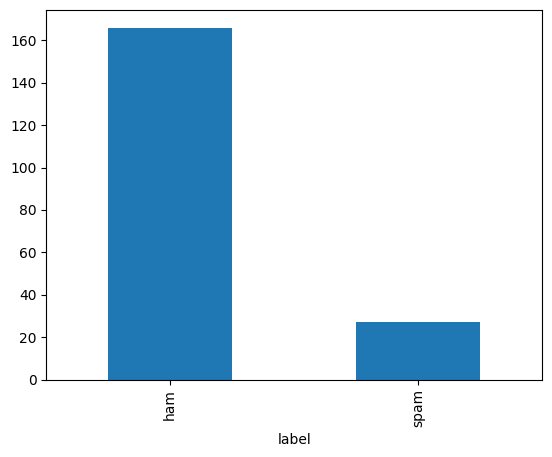

In [ ]:
# TODO: Create a bar chart for label distribution
df['label'].value_counts().plot(kind='bar')

<Axes: ylabel='Frequency'>

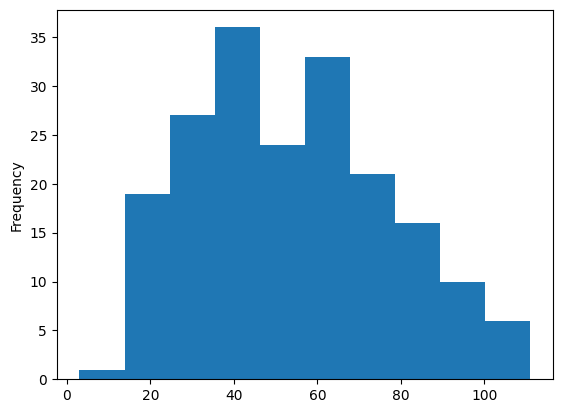

In [ ]:
# TODO: Create a histogram of message length
df['message_length'].plot(kind='hist')

In [ ]:
# Helper function to get common words

from collections import Counter

def get_common_words(text_series, top_n=10):
    all_words = " ".join(text_series).split()
    word_counts = Counter(all_words)
    return pd.DataFrame(word_counts.most_common(top_n), columns=["word", "count"])

In [ ]:
# TODO: Show most common words in spam messages
get_common_words(df[df['label']=='spam']['message'])

,word,count
0,to,22
1,your,15
2,a,10
3,call,10
4,you,9
5,text,7
6,and,7
7,for,7
8,cash,7
9,mobile,6


In [ ]:
# TODO: Show most common words in ham messages
get_common_words(df[df['label']=='ham']['message'])

,word,count
0,i,69
1,to,49
2,you,43
3,the,26
4,and,21
5,have,21
6,a,20
7,in,16
8,my,16
9,for,16


## 7. Prepare Data for Machine Learning

Machine learning models cannot understand raw text directly.

We need to convert text into numbers using **TF-IDF Vectorization**.

### TODO
1. Store cleaned messages in `X`.
2. Store labels in `y`.
3. Split the data into training and testing sets.
4. Use `test_size=0.2`.
5. Use `random_state=42`.
6. Use `stratify=y`.


In [ ]:
# TODO: Create X and y
X=df['message']
y=df['label']

In [ ]:
# TODO: Split the data
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=1)

## 8. Convert Text to Numbers Using TF-IDF

TF-IDF means **Term Frequency - Inverse Document Frequency**.

It gives higher importance to words that are useful for classification.

### TODO
1. Create a `TfidfVectorizer`.
2. Fit it on the training text only.
3. Transform the training and testing text.


In [ ]:
# TODO: Create and apply TF-IDF
vectorizer=TfidfVectorizer()
X_train=vectorizer.fit_transform(X_train)
X_test=vectorizer.transform(X_test)

## 9. Train Different Machine Learning Models

You will compare several classification algorithms:

1. Multinomial Naive Bayes
2. Logistic Regression
3. Linear Support Vector Machine
4. Decision Tree
5. Random Forest

### TODO
Train each model and calculate accuracy.


In [ ]:
# TODO: Create a dictionary of models

models = {
     "Naive Bayes": MultinomialNB(),
     "Logistic Regression": LogisticRegression(max_iter=1000),
     "Linear SVM": LinearSVC(),
     "Decision Tree": DecisionTreeClassifier(random_state=42),
     "Random Forest": RandomForestClassifier(random_state=42)
 }


In [ ]:
# TODO: Train models and store accuracy scores
results=[]
for model_name,model in models.items():
  model.fit(X_train,y_train)
  y_predict=model.predict(X_test)
  accuracy=accuracy_score(y_test,y_predict)

  results.append({
        "Model": model_name,
        "Accuracy": round(accuracy*100)
    })
  print(f'{model_name}: {round(accuracy*100)}%')


Naive Bayes: 86%
Logistic Regression: 84%
Linear SVM: 94%
Decision Tree: 92%
Random Forest: 86%


## 10. Compare Model Accuracy

### TODO
1. Convert model results into a DataFrame.
2. Sort models by accuracy.
3. Create a bar chart comparing accuracy.
4. Identify the best model.


In [ ]:
# TODO: Convert results to DataFrame
results_df=pd.DataFrame(results)
results_df.sort_values(by='Accuracy',ascending=False,inplace=True)
results_df

,Model,Accuracy
2,Linear SVM,94
3,Decision Tree,92
0,Naive Bayes,86
4,Random Forest,86
1,Logistic Regression,84


<Axes: xlabel='Model'>

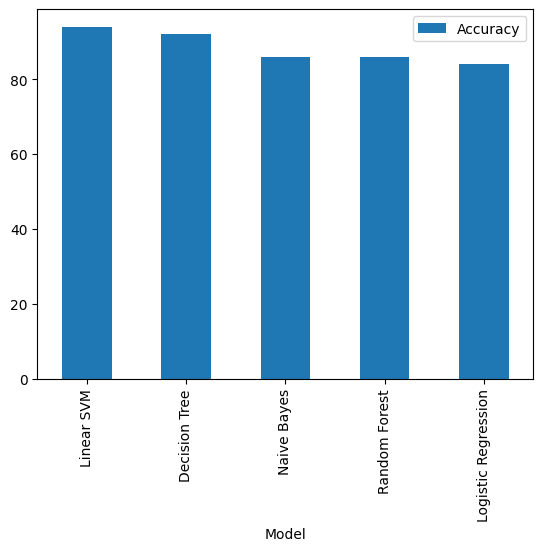

In [ ]:
# TODO: Plot model accuracy comparison
results_df.plot(kind='bar',x='Model',y='Accuracy')

## 11. Evaluate the Best Model

After comparing all models, choose the best one and evaluate it more deeply.

### TODO
1. Choose the best model.
2. Train it again.
3. Predict test messages.
4. Display the confusion matrix.
5. Display the classification report.


In [ ]:
# TODO: Choose the best model name based on your results
best_model="Linear SVM"

In [ ]:
# TODO: Display confusion matrix
best_model=models[best_model]
best_model.fit(X_train,y_train)
y_predict=best_model.predict(X_test)
confusion_matrix(y_test,y_predict)


array([[41,  0],
       [ 3,  5]])

In [ ]:
# TODO: Display classification report
print(classification_report(y_test,y_predict))

              precision    recall  f1-score   support

         ham       0.93      1.00      0.96        41
        spam       1.00      0.62      0.77         8

    accuracy                           0.94        49
   macro avg       0.97      0.81      0.87        49
weighted avg       0.94      0.94      0.93        49



## 12. Test the Model With New Messages

Now try your model with new messages.

### TODO
1. Write new custom messages.
2. Clean the messages.
3. Transform them using the same TF-IDF vectorizer.
4. Predict whether each message is spam or ham.


In [ ]:
# TODO: Try your own messages
new_messages = pd.Series(["Congratulations! You have won a free iPhone. Click here now!",
    "Hey, are we still meeting tomorrow?",
    "Claim your prize now!",
    "Don't forget our meeting at 3 PM."])
new_messages

,0
0,Congratulations! You have won a free iPhone. C...
1,"Hey, are we still meeting tomorrow?"
2,Claim your prize now!
3,Don't forget our meeting at 3 PM.


In [ ]:
cleaned_messages=clean_text(new_messages)
cleaned_messages

,0
0,congratulations! you have won a free iphone. c...
1,"hey, are we still meeting tomorrow?"
2,claim your prize now!
3,don't forget our meeting at 3 pm.


In [ ]:
cleaned_messages_tfidf=vectorizer.transform(cleaned_messages)
cleaned_messages_tfidf

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 21 stored elements and shape (4, 612)>

In [ ]:
final_predictions=best_model.predict(cleaned_messages_tfidf)
final_predictions

array(['ham', 'ham', 'spam', 'ham'], dtype=object)

## 13. Student Questions

Answer the following questions in Markdown cells:

1. What is the difference between spam and ham?
2. Why do we need to clean text before training?
3. What does TF-IDF do?
4. Which words are common in spam messages?
5. Which words are common in ham messages?
6. Which model achieved the highest accuracy?
7. What does the confusion matrix show?
8. How can we improve the model?


In [ ]:
# TODO: Write your answers in a Markdown cell below.
'''
1-ham:normal message
 spam:unwanted promotional or scam message
2-To transforms unstructured text into a uniform format so it preventing confusion and improving accuracy
3-TF = Term Frequency, IDF = Inverse Document Frequency
  it will converts text into numbers while giving more importance to informative words and less importance to very common words.
4-most common words in spam messages:to, your,a, call, you, text, and, for, cash, mobile
5-most common words in ham messages: i, to, you, the, and, have, a, in, my, for
6-Linear SVM model
7-array([[41,  0],
       [ 3,  5]])
table used to measure how well a classification model is performing
8- Gather more data
 - clean the data
 - Ensure that each target category has the same amount of training data to prevent the model from becoming biased toward the majority class
 - Try Different Machine Learning Models
 '''